# Statistical Analysis of a Noisy Digital Communication Link

**Course:** SENG 302 – Statistics for Engineers (Level 300, Semester 2)
**Project type:** Course project – simulation and statistical analysis
**Tools:** Python 3, NumPy, SciPy (`scipy.stats`), Matplotlib – everything runs in Google Colab with no extra installation.

---

## 1. Project description

Every phone call, Wi-Fi download and voice assistant depends on a **digital communication link**. Bits are sent as electrical signals and corrupted by random noise. Packets arrive at random times. Engineers must decide, from uncertain measurements, what was really sent. Uncertainty is everywhere, so statistics is the natural tool for designing and monitoring such a system.

In this project we **simulate a complete communication link** and use every major topic from SENG 302 to analyse it:

* *How many packets arrive each second, and how long are the gaps between them?*
* *How should the receiver decide whether a 0 or a 1 was sent, and how often will it be wrong?*
* *What is the chance that a packet has too many bit errors to be corrected?*
* *Does a second antenna help, and how does noise correlation affect it?*
* *Why is channel noise modelled as normal in the first place?*
* *How accurately can we estimate the error rate from a finite test?*
* *Is a new receiver design really better, or is the difference just chance?*
* *How does the error rate depend on signal strength?*
* *How do we detect when the link develops a fault?*
* *Can we detect when someone is speaking in a noisy audio stream?*

### Problem statement
A telecommunications company runs a digital link that carries data packets and voice traffic over a noisy channel. Its engineers must answer these questions with evidence, not guesswork:

1. **Traffic:** How is packet traffic distributed over time, and how likely are bursts of traffic or idle periods?
2. **Reliability:** How should the receiver decide which bit was sent, and how often will bits and whole packets be lost?
3. **Design:** Does adding a second antenna reduce errors, and how does correlated noise limit the gain?
4. **Measurement:** How precisely can a finite test estimate the error rate, the noise level and the traffic rate?
5. **Decisions:** Is a new receiver significantly better than the old one, or could the difference be due to chance?
6. **Planning:** What signal-to-noise ratio is needed to reach a target error rate?
7. **Monitoring:** How can faults and slow drifts in the link be detected quickly during operation?
8. **Voice:** Can the system tell automatically when someone is speaking, so that a speech recogniser only processes speech?

All of these involve **random behaviour**, so the problem is to build a statistical model of the link and use probability, estimation, hypothesis testing, regression and control charts to answer each question. No real network data is available, so the link is **simulated** with known parameters. That way, every statistical result can be checked against the true value.

### System model
* Packets arrive at random with an average rate of $\lambda$ packets per second.
* Each bit is sent as a voltage: bit 1 → $+A$, bit 0 → $-A$.
* The channel adds Gaussian noise: the receiver sees $R = S + N$, with $N \sim \mathcal N(0, \sigma^2)$.
* Each packet has $n = 128$ bits and an error-correcting code that can fix up to $t = 2$ bit errors.

### Objectives
1. Model packet traffic with the **Poisson** and **exponential** distributions (discrete and continuous random variables).
2. Design the receiver's decision rule with **conditional probability** and **Bayes' theorem**, using the **normal** distribution.
3. Use **counting techniques** and the **binomial** distribution to find packet failure probabilities.
4. Use **joint distributions, covariance and correlation** to analyse a two-antenna receiver.
5. Demonstrate the **central limit theorem** and **sampling distributions**.
6. **Estimate** the error rate, noise level and arrival rate with confidence intervals.
7. Use **hypothesis testing** to compare receivers and to understand Type I and Type II errors.
8. Use **regression analysis** to model error rate against signal-to-noise ratio.
9. Apply **statistical quality control and process control** charts to monitor the link.
10. Build a simple statistical **speech detector** (the first stage of speech recognition).

### Course topics mapped to notebook sections

| # | Section | SENG 302 topics used |
|---|---|---|
| 2 | Packet arrivals | Discrete and continuous random variables, Poisson distribution, exponential distribution, memoryless property |
| 3 | Detecting bits in noise | Normal distribution, conditional probability, Bayes' theorem, law of total probability |
| 4 | Bit errors in a packet | Counting techniques (multiplication rule, permutations, combinations), binomial distribution, Poisson approximation |
| 5 | Two-antenna receiver | Joint distributions, marginal distributions, independence, covariance, correlation |
| 6 | Why noise is normal | Central limit theorem, sampling distribution of the mean |
| 7 | Estimation | Point estimates, confidence intervals for a proportion, mean and variance (z, t and chi-square) |
| 8 | Hypothesis testing | One-sample t-test, two-proportion z-test, p-values, Type I and Type II errors, power, ROC curve |
| 9 | Error rate vs signal strength | Simple and multiple linear regression, R², residual analysis, prediction |
| 10 | Monitoring the link | Quality control (p-chart), process control (x̄-chart), out-of-control rules |
| 11 | Speech detection | Statistical classification for speech recognition, Gaussian models, Bayes decision rule, error rates |
| 12 | Conclusion | Summary of results |

### How to run
Open this notebook in Google Colab and choose **Runtime → Run all**. All parameters are set in Section 1. A fixed random seed makes the results repeatable. Change the seed or the parameters and re-run to explore other scenarios.

## 1. Setup and parameters

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from math import comb, perm

plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(302)          # fixed seed so results are repeatable

LAM = 4.0            # mean packet arrival rate (packets per second)
A = 1.0              # signal amplitude: bit 1 -> +A, bit 0 -> -A
TARGET_BER = 0.01    # noise level is chosen so the basic receiver has a 1% bit error rate
SIGMA = A / stats.norm.isf(TARGET_BER)     # noise standard deviation
N_BITS = 128         # bits per packet
T_CORRECT = 2        # the error-correcting code fixes up to 2 bit errors per packet

print(f"Arrival rate λ = {LAM} packets/s")
print(f"Signal amplitude A = {A}, noise σ = {SIGMA:.4f}, SNR = {10*np.log10(A**2/SIGMA**2):.2f} dB")
print(f"Packet length n = {N_BITS} bits, correctable errors t = {T_CORRECT}")

Arrival rate λ = 4.0 packets/s
Signal amplitude A = 1.0, noise σ = 0.4299, SNR = 7.33 dB
Packet length n = 128 bits, correctable errors t = 2


## 2. Packet arrivals: Poisson and exponential random variables

Packets arrive independently at a constant average rate $\lambda$. Two random variables describe this traffic:

| Random variable | Type | Distribution | Mean | Variance |
|---|---|---|---|---|
| $X$ = packets in one second | **discrete** (0, 1, 2, …) | Poisson: $P(X=x) = \dfrac{e^{-\lambda}\lambda^x}{x!}$ | $\lambda$ | $\lambda$ |
| $T$ = gap between packets | **continuous** ($t \ge 0$) | Exponential: $f(t) = \lambda e^{-\lambda t}$ | $1/\lambda$ | $1/\lambda^2$ |

A discrete variable has a **probability mass function** (pmf), and its probabilities add up to 1. A continuous variable has a **probability density function** (pdf). Its probabilities are areas under the curve, so $P(T = t_0) = 0$ for any single value.

We simulate exponential gaps, add them up to get arrival times, and then count the arrivals in each second. If the theory is right, the counts should follow a Poisson distribution.

In [2]:
gaps = rng.exponential(scale=1 / LAM, size=40_000)      # continuous: time between packets
arrival_times = np.cumsum(gaps)
duration = int(arrival_times[-1])                       # whole seconds observed
counts = np.bincount(arrival_times[arrival_times < duration].astype(int), minlength=duration)

print(f"Observed {duration} seconds containing {counts.sum()} packets\n")
print(f"Packets per second  : sample mean = {counts.mean():.3f}, sample variance = {counts.var(ddof=1):.3f}"
      f"   (Poisson theory: both = {LAM})")
print(f"Gap between packets : sample mean = {gaps.mean():.4f} s, sample sd = {gaps.std(ddof=1):.4f} s"
      f"   (Exponential theory: both = {1/LAM})")

Observed 10008 seconds containing 39994 packets

Packets per second  : sample mean = 3.996, sample variance = 3.983   (Poisson theory: both = 4.0)
Gap between packets : sample mean = 0.2502 s, sample sd = 0.2478 s   (Exponential theory: both = 0.25)


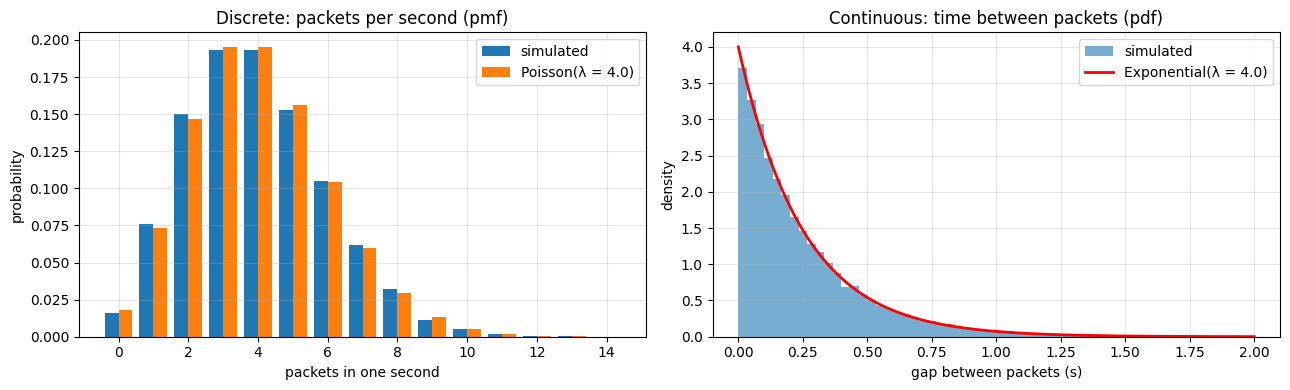

In [3]:
k = np.arange(0, 15)
emp_pmf = np.array([(counts == kk).mean() for kk in k])
xs = np.linspace(0, 2, 300)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].bar(k - 0.2, emp_pmf, width=0.4, label="simulated")
axs[0].bar(k + 0.2, stats.poisson.pmf(k, LAM), width=0.4, label=f"Poisson(λ = {LAM})")
axs[0].set(xlabel="packets in one second", ylabel="probability", title="Discrete: packets per second (pmf)")
axs[0].legend()
axs[1].hist(gaps, bins=60, range=(0, 2), density=True, alpha=0.6, label="simulated")
axs[1].plot(xs, stats.expon.pdf(xs, scale=1 / LAM), "r", lw=2, label=f"Exponential(λ = {LAM})")
axs[1].set(xlabel="gap between packets (s)", ylabel="density", title="Continuous: time between packets (pdf)")
axs[1].legend()
plt.tight_layout()
plt.show()

In [4]:
print("Probability questions                          theory    simulated")
print(f"P(no packets in a second)                     {stats.poisson.pmf(0, LAM):8.4f}   {(counts == 0).mean():8.4f}")
print(f"P(8 or more packets in a second)              {stats.poisson.sf(7, LAM):8.4f}   {(counts >= 8).mean():8.4f}")
print(f"P(gap longer than 0.5 s)                      {stats.expon.sf(0.5, scale=1/LAM):8.4f}   {(gaps > 0.5).mean():8.4f}")
print(f"P(0.1 s < gap < 0.3 s) = F(0.3) - F(0.1)      "
      f"{stats.expon.cdf(0.3, scale=1/LAM) - stats.expon.cdf(0.1, scale=1/LAM):8.4f}   {((gaps > 0.1) & (gaps < 0.3)).mean():8.4f}")

# Memoryless property: P(T > s + t | T > s) = P(T > t)
s_, t_ = 0.25, 0.25
conditional = (gaps > s_ + t_).sum() / (gaps > s_).sum()
print(f"\nMemoryless check: P(T > 0.5 | T > 0.25) = {conditional:.4f}  vs  P(T > 0.25) = {(gaps > t_).mean():.4f}"
      f"  (theory {np.exp(-LAM * t_):.4f})")
print("Waiting 0.25 s without a packet does not change the chance of waiting another 0.25 s.")

Probability questions                          theory    simulated
P(no packets in a second)                       0.0183     0.0162
P(8 or more packets in a second)                0.0511     0.0509
P(gap longer than 0.5 s)                        0.1353     0.1360
P(0.1 s < gap < 0.3 s) = F(0.3) - F(0.1)        0.3691     0.3663

Memoryless check: P(T > 0.5 | T > 0.25) = 0.3670  vs  P(T > 0.25) = 0.3705  (theory 0.3679)
Waiting 0.25 s without a packet does not change the chance of waiting another 0.25 s.


## 3. Detecting bits in noise: normal distribution, conditional probability and Bayes' theorem

The receiver sees $R = S + N$ with $N \sim \mathcal N(0,\sigma^2)$. Given the bit that was sent, $R$ is normal:
$$R \mid (\text{bit}=1) \sim \mathcal N(+A, \sigma^2), \qquad R \mid (\text{bit}=0) \sim \mathcal N(-A, \sigma^2).$$

The receiver needs the **reverse** conditional probability, which comes from **Bayes' theorem**:
$$P(\text{bit}=1 \mid R=r) = \frac{P_1\, f(r\mid 1)}{P_1\, f(r\mid 1) + P_0\, f(r\mid 0)} .$$

* **Maximum-likelihood (ML) rule:** decide 1 if $r > 0$. This is best when $P_0 = P_1$.
* **Maximum a posteriori (MAP) rule:** decide 1 if $P(1\mid r) > P(0\mid r)$. This is equivalent to $r > \tau$ with
$$\tau = \frac{\sigma^2}{2A}\ln\frac{P_0}{P_1}.$$

By the **law of total probability**, the overall error probability is
$$P(\text{error}) = P_0\,P(R>\tau \mid 0) + P_1\,P(R<\tau \mid 1).$$

In [5]:
def map_threshold(p1, sigma=SIGMA, a=A):
    return sigma**2 / (2 * a) * np.log((1 - p1) / p1)

def error_probability(tau, p1, sigma=SIGMA, a=A):
    p0 = 1 - p1
    p_err_given_0 = stats.norm.sf(tau, loc=-a, scale=sigma)    # sent 0, decided 1
    p_err_given_1 = stats.norm.cdf(tau, loc=a, scale=sigma)    # sent 1, decided 0
    return p0 * p_err_given_0 + p1 * p_err_given_1             # law of total probability

def transmit(n, p1=0.5, sigma=SIGMA):
    # Sends n random bits through the noisy channel; returns (bits, received voltages)
    bits = rng.random(n) < p1
    received = np.where(bits, A, -A) + rng.normal(0, sigma, n)
    return bits, received

print(f"Equal priors, ML rule: theoretical BER = {error_probability(0.0, 0.5):.4f}  (target {TARGET_BER})")

P1 = 0.7          # an unbalanced source: 70% of bits are 1s
bits, received = transmit(1_000_000, p1=P1)
print(f"\nUnequal priors P(1) = {P1}:")
for name, tau in [("ML  rule (τ = 0)", 0.0), ("MAP rule", map_threshold(P1))]:
    simulated = np.mean((received > tau) != bits)
    print(f"  {name:18s} τ = {tau:+.4f}   theory BER = {error_probability(tau, P1):.5f}   simulated BER = {simulated:.5f}")
print("The MAP rule uses the prior information and gives the lower error rate.")

Equal priors, ML rule: theoretical BER = 0.0100  (target 0.01)

Unequal priors P(1) = 0.7:
  ML  rule (τ = 0)   τ = +0.0000   theory BER = 0.01000   simulated BER = 0.01009
  MAP rule           τ = -0.0783   theory BER = 0.00905   simulated BER = 0.00917
The MAP rule uses the prior information and gives the lower error rate.


r = -0.5  ->  P(bit = 1 | r) = 0.0103
r = -0.1  ->  P(bit = 1 | r) = 0.4415
r = +0.0  ->  P(bit = 1 | r) = 0.7000
r = +0.1  ->  P(bit = 1 | r) = 0.8732
r = +0.5  ->  P(bit = 1 | r) = 0.9981

P(R > 0): total probability = 0.6960,  simulated = 0.6959


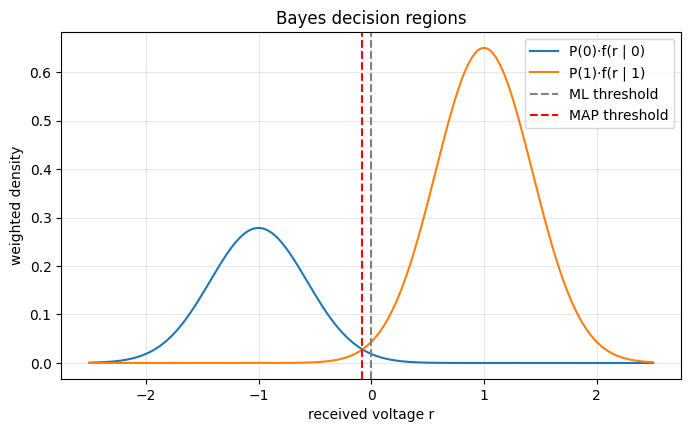

In [6]:
# Bayes' theorem for individual received values
def posterior_one(r, p1=P1, sigma=SIGMA):
    like1 = stats.norm.pdf(r, loc=A, scale=sigma)
    like0 = stats.norm.pdf(r, loc=-A, scale=sigma)
    return p1 * like1 / (p1 * like1 + (1 - p1) * like0)

for r in [-0.5, -0.1, 0.0, 0.1, 0.5]:
    print(f"r = {r:+.1f}  ->  P(bit = 1 | r) = {posterior_one(r):.4f}")

# Law of total probability for P(R > 0)
p_r_pos = P1 * stats.norm.sf(0, loc=A, scale=SIGMA) + (1 - P1) * stats.norm.sf(0, loc=-A, scale=SIGMA)
print(f"\nP(R > 0): total probability = {p_r_pos:.4f},  simulated = {(received > 0).mean():.4f}")

rs = np.linspace(-2.5, 2.5, 500)
fig, ax = plt.subplots()
ax.plot(rs, (1 - P1) * stats.norm.pdf(rs, -A, SIGMA), label="P(0)·f(r | 0)")
ax.plot(rs, P1 * stats.norm.pdf(rs, A, SIGMA), label="P(1)·f(r | 1)")
ax.axvline(0, color="gray", ls="--", label="ML threshold")
ax.axvline(map_threshold(P1), color="r", ls="--", label="MAP threshold")
ax.set(xlabel="received voltage r", ylabel="weighted density", title="Bayes decision regions")
ax.legend()
plt.show()

## 4. Bit errors in a packet: counting techniques and the binomial distribution

### 4.1 Counting
* **Multiplication rule:** a packet of $n$ bits can take $2^n$ different values.
* **Combinations:** the number of different positions for exactly $k$ errors among $n$ bits is $\binom{n}{k}$.
* **Permutations:** if 3 urgent packets are placed into 3 of 10 time slots and the order matters, there are $P(10,3) = \frac{10!}{7!}$ schedules.

### 4.2 Binomial model
Each bit is wrong with probability $p$, independently. So the number of errors per packet is $X \sim \text{Binomial}(n, p)$:
$$P(X = k) = \binom{n}{k} p^k (1-p)^{n-k}.$$
The packet **fails** if $X > t$. When $n$ is large and $p$ is small, $X$ is approximately $\text{Poisson}(np)$.

In [7]:
P_BIT = TARGET_BER
print(f"Possible {N_BITS}-bit packets (multiplication rule): 2^{N_BITS} = {2**N_BITS:.3e}")
for kk in range(4):
    print(f"Error patterns with exactly {kk} errors: C({N_BITS},{kk}) = {comb(N_BITS, kk):,}")
print(f"Schedules for 3 urgent packets in 10 slots: P(10,3) = {perm(10, 3)}")

# Packet failure probability: binomial, written out with the counting formula
p_ok = sum(comb(N_BITS, kk) * P_BIT**kk * (1 - P_BIT)**(N_BITS - kk) for kk in range(T_CORRECT + 1))
P_FAIL = 1 - p_ok
print(f"\nP(packet fails) = 1 - Σ_(k=0..{T_CORRECT}) C(n,k) p^k (1-p)^(n-k) = {P_FAIL:.5f}")
print(f"Same using scipy binom.sf          = {stats.binom.sf(T_CORRECT, N_BITS, P_BIT):.5f}")
print(f"Poisson approximation (λ = np = {N_BITS*P_BIT:.2f}) = {stats.poisson.sf(T_CORRECT, N_BITS*P_BIT):.5f}")

Possible 128-bit packets (multiplication rule): 2^128 = 3.403e+38
Error patterns with exactly 0 errors: C(128,0) = 1
Error patterns with exactly 1 errors: C(128,1) = 128
Error patterns with exactly 2 errors: C(128,2) = 8,128
Error patterns with exactly 3 errors: C(128,3) = 341,376
Schedules for 3 urgent packets in 10 slots: P(10,3) = 720

P(packet fails) = 1 - Σ_(k=0..2) C(n,k) p^k (1-p)^(n-k) = 0.13748
Same using scipy binom.sf          = 0.13748
Poisson approximation (λ = np = 1.28) = 0.13831


Simulated: mean errors per packet = 1.2809 (theory np = 1.2800)
Simulated: variance               = 1.2538 (theory np(1-p) = 1.2672)
Simulated packet failure rate     = 0.13505 (theory 0.13748)


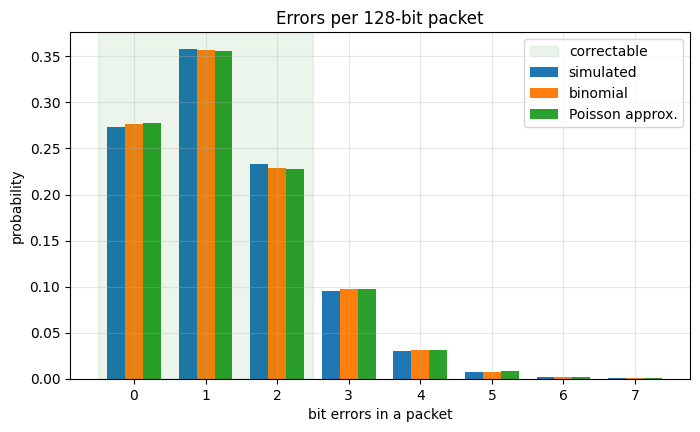

In [8]:
# Simulate real packets through the channel and count errors in each
n_packets = 20_000
bits, received = transmit(n_packets * N_BITS)
errors_per_packet = ((received > 0) != bits).reshape(n_packets, N_BITS).sum(axis=1)

print(f"Simulated: mean errors per packet = {errors_per_packet.mean():.4f} (theory np = {N_BITS*P_BIT:.4f})")
print(f"Simulated: variance               = {errors_per_packet.var(ddof=1):.4f} (theory np(1-p) = {N_BITS*P_BIT*(1-P_BIT):.4f})")
print(f"Simulated packet failure rate     = {(errors_per_packet > T_CORRECT).mean():.5f} (theory {P_FAIL:.5f})")

kk = np.arange(0, 8)
fig, ax = plt.subplots()
ax.bar(kk - 0.25, [(errors_per_packet == v).mean() for v in kk], width=0.25, label="simulated")
ax.bar(kk, stats.binom.pmf(kk, N_BITS, P_BIT), width=0.25, label="binomial")
ax.bar(kk + 0.25, stats.poisson.pmf(kk, N_BITS * P_BIT), width=0.25, label="Poisson approx.")
ax.axvspan(-0.5, T_CORRECT + 0.5, color="green", alpha=0.08, label="correctable")
ax.set(xlabel="bit errors in a packet", ylabel="probability", title="Errors per 128-bit packet")
ax.legend()
plt.show()

## 5. Two-antenna receiver: joint distributions, covariance and correlation

A second antenna receives the same bit with its own noise. The noises $(N_1, N_2)$ have a **bivariate normal** joint distribution with correlation $\rho$:
$$\operatorname{Cov}(N_1,N_2) = \rho\sigma^2, \qquad \rho = \frac{\operatorname{Cov}(N_1,N_2)}{\sigma_{N_1}\sigma_{N_2}} .$$

The receiver averages the two signals. Using $\operatorname{Var}(aX+bY) = a^2\operatorname{Var}X + b^2\operatorname{Var}Y + 2ab\operatorname{Cov}(X,Y)$:
$$\operatorname{Var}\!\left(\frac{N_1+N_2}{2}\right) = \frac{\sigma^2(1+\rho)}{2}, \qquad \text{BER} = Q\!\left(\frac{A}{\sigma\sqrt{(1+\rho)/2}}\right).$$
If the noises are independent ($\rho = 0$), the noise variance is halved. If they are highly correlated ($\rho \to 1$), the second antenna adds almost nothing.

In [9]:
def two_antenna_ber(rho):
    return stats.norm.sf(A / (SIGMA * np.sqrt((1 + rho) / 2)))

def transmit_two_antennas(n, rho):
    cov = SIGMA**2 * np.array([[1, rho], [rho, 1]])
    noise = rng.multivariate_normal([0, 0], cov, size=n)
    bits = rng.random(n) < 0.5
    s = np.where(bits, A, -A)
    return bits, s + noise[:, 0], s + noise[:, 1], noise

n_two = 500_000
joint_results = {}
print(f"Single antenna BER = {TARGET_BER:.5f}\n")
print(" ρ     sample Cov   theory Cov   sample corr   BER theory   BER simulated")
for rho in [0.0, 0.5, 0.9]:
    bits, r1, r2, noise = transmit_two_antennas(n_two, rho)
    combined = (r1 + r2) / 2
    ber_sim = np.mean((combined > 0) != bits)
    sample_cov = np.cov(noise[:, 0], noise[:, 1])[0, 1]
    sample_corr = np.corrcoef(noise[:, 0], noise[:, 1])[0, 1]
    print(f"{rho:3.1f}   {sample_cov:10.5f}   {rho*SIGMA**2:10.5f}   {sample_corr:11.4f}   "
          f"{two_antenna_ber(rho):10.5f}   {ber_sim:13.5f}")
    joint_results[rho] = (noise[:3000], (r1 > 0) != bits, (r2 > 0) != bits)

Single antenna BER = 0.01000

 ρ     sample Cov   theory Cov   sample corr   BER theory   BER simulated
0.0     -0.00041      0.00000       -0.0022      0.00050         0.00048
0.5      0.09222      0.09239        0.4998      0.00361         0.00360
0.9      0.16677      0.16630        0.9003      0.00850         0.00852


### Joint distribution of the two antennas' errors
Let $E_1$ and $E_2$ be the events that antenna 1 and antenna 2 each get the bit wrong on their own. Below is their **joint probability table**, with **marginal** totals. The two events are **independent** only if $P(E_1 \cap E_2) = P(E_1)P(E_2)$.

ρ = 0.0:
               E2 = no     E2 = yes   | marginal
  E1 = no      0.97995    0.01000   | 0.98995
  E1 = yes     0.00994    0.00010   | 0.01005
  marginal     0.98989    0.01011
  P(E1 ∩ E2) = 0.000102   vs   P(E1)·P(E2) = 0.000102
  P(E2 | E1) = 0.0102   vs   P(E2) = 0.0101

ρ = 0.5:
               E2 = no     E2 = yes   | marginal
  E1 = no      0.98202    0.00846   | 0.99048
  E1 = yes     0.00822    0.00130   | 0.00952
  marginal     0.99024    0.00976
  P(E1 ∩ E2) = 0.001302   vs   P(E1)·P(E2) = 0.000093
  P(E2 | E1) = 0.1368   vs   P(E2) = 0.0098

ρ = 0.9:
               E2 = no     E2 = yes   | marginal
  E1 = no      0.98543    0.00457   | 0.99000
  E1 = yes     0.00450    0.00549   | 0.01000
  marginal     0.98993    0.01007
  P(E1 ∩ E2) = 0.005494   vs   P(E1)·P(E2) = 0.000101
  P(E2 | E1) = 0.5496   vs   P(E2) = 0.0101



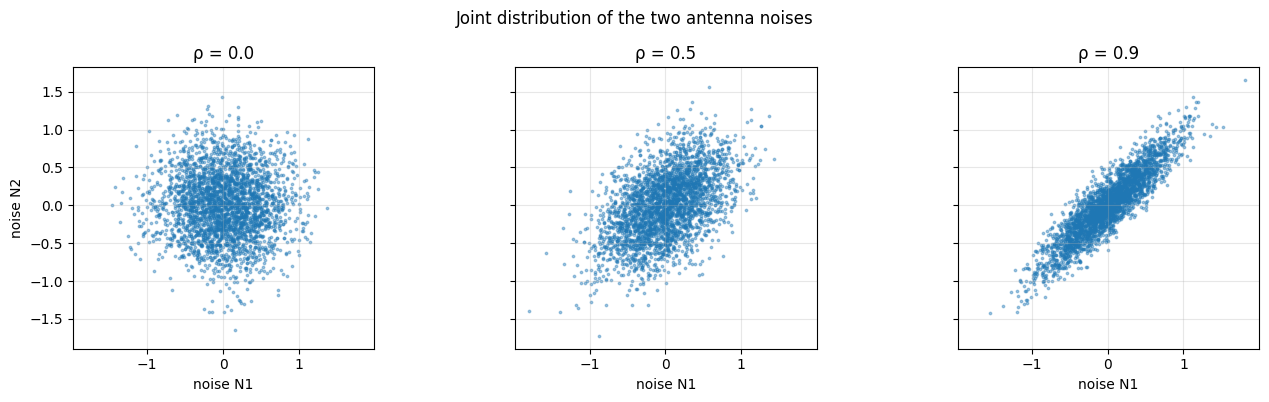

In [10]:
for rho, (_, e1, e2) in joint_results.items():
    table = np.array([[np.mean(~e1 & ~e2), np.mean(~e1 & e2)],
                      [np.mean(e1 & ~e2),  np.mean(e1 & e2)]])
    p_e1, p_e2 = table[1].sum(), table[:, 1].sum()          # marginal probabilities
    print(f"ρ = {rho}:")
    print(f"               E2 = no     E2 = yes   | marginal")
    print(f"  E1 = no    {table[0,0]:9.5f}  {table[0,1]:9.5f}   | {table[0].sum():.5f}")
    print(f"  E1 = yes   {table[1,0]:9.5f}  {table[1,1]:9.5f}   | {p_e1:.5f}")
    print(f"  marginal   {table[:,0].sum():9.5f}  {p_e2:9.5f}")
    print(f"  P(E1 ∩ E2) = {table[1,1]:.6f}   vs   P(E1)·P(E2) = {p_e1*p_e2:.6f}")
    print(f"  P(E2 | E1) = {table[1,1]/p_e1:.4f}   vs   P(E2) = {p_e2:.4f}\n")

fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
for ax, (rho, (noise_sample, _, _)) in zip(axs, joint_results.items()):
    ax.scatter(noise_sample[:, 0], noise_sample[:, 1], s=3, alpha=0.4)
    ax.set(title=f"ρ = {rho}", xlabel="noise N1")
    ax.set_aspect("equal")
axs[0].set_ylabel("noise N2")
fig.suptitle("Joint distribution of the two antenna noises")
plt.tight_layout()
plt.show()

## 6. Why is noise normal? The central limit theorem and sampling distributions

### 6.1 Central limit theorem
Channel noise is the **sum of many small independent disturbances** (thermal motion of electrons, interference, and so on). The **central limit theorem** says that the standardised sum of $m$ independent, identically distributed variables tends to $\mathcal N(0,1)$ as $m$ grows, *whatever their original distribution*. Below, each disturbance is strongly skewed (exponential), yet their sum becomes normal.

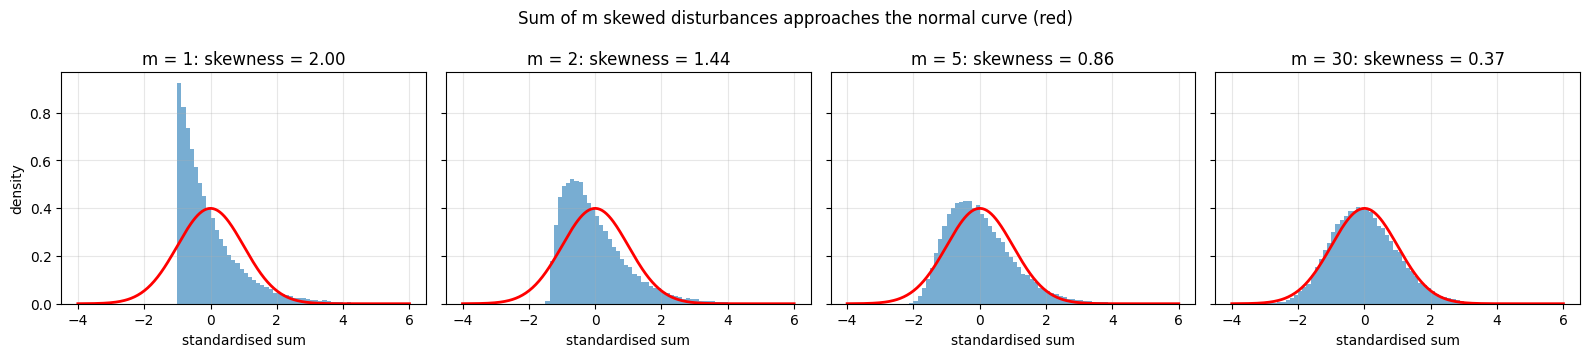

Theoretical skewness of the standardised sum is 2/√m: [np.float64(2.0), np.float64(1.41), np.float64(0.89), np.float64(0.37)]


In [11]:
z = np.linspace(-4, 6, 300)
fig, axs = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, m in zip(axs, [1, 2, 5, 30]):
    sums = rng.exponential(1.0, size=(50_000, m)).sum(axis=1)
    standardised = (sums - m) / np.sqrt(m)                 # mean m, variance m
    ax.hist(standardised, bins=80, range=(-4, 6), density=True, alpha=0.6)
    ax.plot(z, stats.norm.pdf(z), "r", lw=2)
    ax.set_title(f"m = {m}: skewness = {stats.skew(standardised):.2f}")
    ax.set_xlabel("standardised sum")
axs[0].set_ylabel("density")
fig.suptitle("Sum of m skewed disturbances approaches the normal curve (red)")
plt.tight_layout()
plt.show()
print("Theoretical skewness of the standardised sum is 2/√m:", [round(2 / np.sqrt(m), 2) for m in [1, 2, 5, 30]])

### 6.2 Sampling distribution of the sample mean
If we measure $n$ packet gaps and compute their mean $\bar T$, then $\bar T$ is itself a random variable. Its **sampling distribution** has
$$E[\bar T] = \mu = \frac1\lambda, \qquad \operatorname{SD}(\bar T) = \frac{\sigma}{\sqrt n} = \frac{1/\lambda}{\sqrt n},$$
and by the CLT it is approximately normal for large $n$.

n =  2: mean of sample means = 0.2495 (theory 0.2500),  SD = 0.1755 (theory σ/√n = 0.1768)
n =  5: mean of sample means = 0.2505 (theory 0.2500),  SD = 0.1103 (theory σ/√n = 0.1118)
n = 30: mean of sample means = 0.2501 (theory 0.2500),  SD = 0.0453 (theory σ/√n = 0.0456)


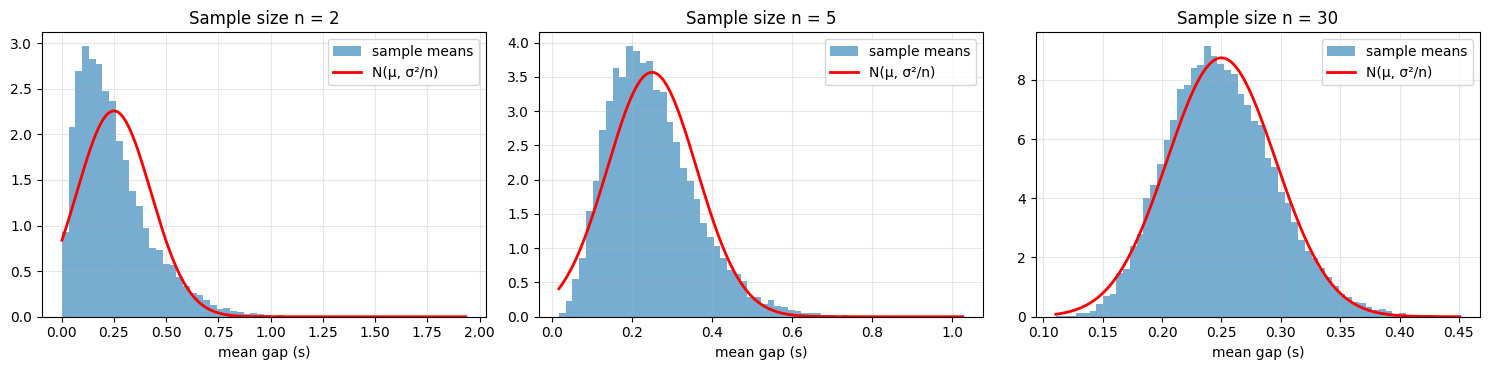

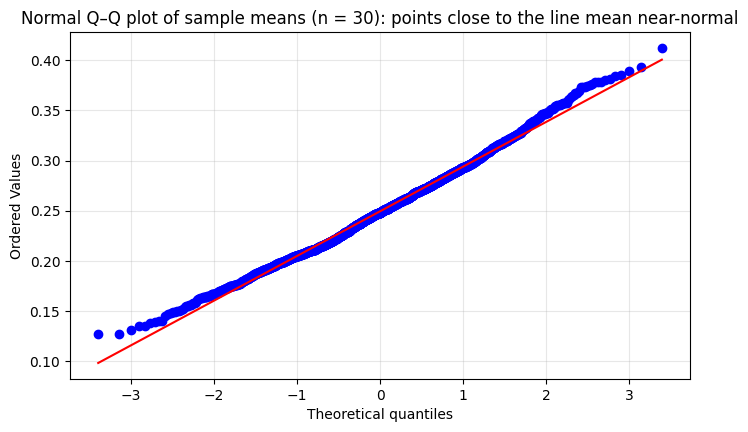

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, n in zip(axs, [2, 5, 30]):
    means = rng.choice(gaps, size=(20_000, n)).mean(axis=1)
    se = (1 / LAM) / np.sqrt(n)
    print(f"n = {n:2d}: mean of sample means = {means.mean():.4f} (theory {1/LAM:.4f}),"
          f"  SD = {means.std(ddof=1):.4f} (theory σ/√n = {se:.4f})")
    xs = np.linspace(means.min(), means.max(), 300)
    ax.hist(means, bins=60, density=True, alpha=0.6, label="sample means")
    ax.plot(xs, stats.norm.pdf(xs, 1 / LAM, se), "r", lw=2, label="N(μ, σ²/n)")
    ax.set(title=f"Sample size n = {n}", xlabel="mean gap (s)")
    ax.legend()
plt.tight_layout()
plt.show()

stats.probplot(rng.choice(gaps, size=(2_000, 30)).mean(axis=1), dist="norm", plot=plt)
plt.title("Normal Q–Q plot of sample means (n = 30): points close to the line mean near-normal")
plt.show()

## 7. Estimation: point estimates and confidence intervals

In a real test we never know the true error rate or noise level. We **estimate** them from a finite sample.

| Parameter | Point estimate | 95% confidence interval |
|---|---|---|
| Bit error rate $p$ | $\hat p = \dfrac{\text{errors}}{n}$ | Wald: $\hat p \pm z_{0.025}\sqrt{\hat p(1-\hat p)/n}$; Wilson score interval (more reliable for small $p$) |
| Noise mean (DC offset) $\mu$ | $\bar x$ | $\bar x \pm t_{0.025,\,n-1}\, s/\sqrt n$ |
| Noise variance $\sigma^2$ | $s^2$ | $\left(\dfrac{(n-1)s^2}{\chi^2_{0.025,\,n-1}},\ \dfrac{(n-1)s^2}{\chi^2_{0.975,\,n-1}}\right)$ |
| Arrival rate $\lambda$ | $\hat\lambda = 1/\bar T$ | invert the CI for the mean gap $1/\lambda$ |

In [13]:
Z95 = stats.norm.isf(0.025)

def wald_ci(errors, n):
    p_hat = errors / n
    half = Z95 * np.sqrt(p_hat * (1 - p_hat) / n)
    return p_hat - half, p_hat + half

def wilson_ci(errors, n):
    p_hat = errors / n
    centre = (p_hat + Z95**2 / (2 * n)) / (1 + Z95**2 / n)
    half = Z95 * np.sqrt(p_hat * (1 - p_hat) / n + Z95**2 / (4 * n**2)) / (1 + Z95**2 / n)
    return centre - half, centre + half

n_test = 20_000
bits, received = transmit(n_test)
errors = int(np.sum((received > 0) != bits))
print(f"Test of {n_test} bits: {errors} errors -> point estimate p̂ = {errors/n_test:.5f} (true p = {TARGET_BER})")
print("95% Wald CI   = ({:.5f}, {:.5f})".format(*wald_ci(errors, n_test)))
print("95% Wilson CI = ({:.5f}, {:.5f})".format(*wilson_ci(errors, n_test)))

Test of 20000 bits: 196 errors -> point estimate p̂ = 0.00980 (true p = 0.01)
95% Wald CI   = (0.00843, 0.01117)
95% Wilson CI = (0.00853, 0.01126)


**What does "95% confidence" mean?** If we repeated the test many times, about 95% of the intervals would contain the true $p$. We check this by repeating a short test (2,000 bits) 5,000 times. When $p$ is small, the Wald interval covers $p$ less often than promised. The Wilson interval stays closer to 95%.

In [14]:
n_short, reps = 2_000, 5_000
error_counts = rng.binomial(n_short, TARGET_BER, size=reps)
wald_lo, wald_hi = wald_ci(error_counts, n_short)
wil_lo, wil_hi = wilson_ci(error_counts, n_short)
print(f"Coverage of 95% Wald intervals   : {np.mean((wald_lo <= TARGET_BER) & (TARGET_BER <= wald_hi)):.3f}")
print(f"Coverage of 95% Wilson intervals : {np.mean((wil_lo <= TARGET_BER) & (TARGET_BER <= wil_hi)):.3f}")

Coverage of 95% Wald intervals   : 0.951
Coverage of 95% Wilson intervals : 0.941


In [15]:
# Noise-only measurements (transmitter switched off): estimate mean and variance
n_noise = 50
noise_sample = rng.normal(0, SIGMA, n_noise)
x_bar, s = noise_sample.mean(), noise_sample.std(ddof=1)

t_crit = stats.t.isf(0.025, n_noise - 1)
mean_ci = (x_bar - t_crit * s / np.sqrt(n_noise), x_bar + t_crit * s / np.sqrt(n_noise))
chi_hi, chi_lo = stats.chi2.isf(0.025, n_noise - 1), stats.chi2.isf(0.975, n_noise - 1)
var_ci = ((n_noise - 1) * s**2 / chi_hi, (n_noise - 1) * s**2 / chi_lo)

print(f"Noise mean    : x̄ = {x_bar:+.4f},  95% t-CI = ({mean_ci[0]:+.4f}, {mean_ci[1]:+.4f})   (true 0)")
print(f"Noise variance: s² = {s**2:.4f},  95% χ²-CI = ({var_ci[0]:.4f}, {var_ci[1]:.4f})   (true {SIGMA**2:.4f})")
print(f"Noise sd      : s = {s:.4f},  95% CI = ({np.sqrt(var_ci[0]):.4f}, {np.sqrt(var_ci[1]):.4f})   (true {SIGMA:.4f})")

# Arrival rate from 200 measured gaps
gap_sample = rng.choice(gaps, size=200)
g_bar, g_s = gap_sample.mean(), gap_sample.std(ddof=1)
gap_ci = (g_bar - Z95 * g_s / np.sqrt(200), g_bar + Z95 * g_s / np.sqrt(200))
print(f"\nArrival rate  : λ̂ = 1/T̄ = {1/g_bar:.3f} packets/s,  95% CI = ({1/gap_ci[1]:.3f}, {1/gap_ci[0]:.3f})   (true {LAM})")

Noise mean    : x̄ = -0.0185,  95% t-CI = (-0.1301, +0.0931)   (true 0)
Noise variance: s² = 0.1543,  95% χ²-CI = (0.1077, 0.2396)   (true 0.1848)
Noise sd      : s = 0.3928,  95% CI = (0.3281, 0.4895)   (true 0.4299)

Arrival rate  : λ̂ = 1/T̄ = 4.855 packets/s,  95% CI = (4.274, 5.617)   (true 4.0)


## 8. Hypothesis testing

### 8.1 One-sample t-test: does the receiver have a DC offset?
A faulty amplifier can add a constant offset $\mu$ to the noise and bias every decision. We test
$$H_0: \mu = 0 \quad\text{vs}\quad H_1: \mu \ne 0, \qquad t = \frac{\bar x - 0}{s/\sqrt n} \sim t_{n-1} \text{ under } H_0 .$$
We test two receivers: a healthy one, and one with a true offset of 0.1 V.

In [16]:
ALPHA = 0.05
for name, offset in [("Healthy receiver", 0.0), ("Faulty receiver ", 0.1)]:
    sample = rng.normal(offset, SIGMA, 100)
    t_stat, p_value = stats.ttest_1samp(sample, popmean=0.0)
    decision = "reject H0 (offset detected)" if p_value < ALPHA else "do not reject H0"
    print(f"{name}: x̄ = {sample.mean():+.4f}, t = {t_stat:+.3f}, p-value = {p_value:.4f}  ->  {decision}")

Healthy receiver: x̄ = -0.0176, t = -0.365, p-value = 0.7158  ->  do not reject H0
Faulty receiver : x̄ = +0.1339, t = +2.983, p-value = 0.0036  ->  reject H0 (offset detected)


### 8.2 Two-proportion z-test: is the two-antenna receiver really better?
Old receiver: single antenna. New receiver: two antennas with $\rho = 0.5$. We send $n$ bits through each one and test
$$H_0: p_{\text{new}} = p_{\text{old}} \quad\text{vs}\quad H_1: p_{\text{new}} < p_{\text{old}}, \qquad z = \frac{\hat p_{\text{old}} - \hat p_{\text{new}}}{\sqrt{\bar p(1-\bar p)\left(\frac1{n_1}+\frac1{n_2}\right)}} .$$

In [17]:
def two_proportion_z(x1, n1, x2, n2):
    # One-sided test of H1: p2 < p1. Returns (z, p-value).
    p1_hat, p2_hat = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    se = np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    with np.errstate(divide="ignore", invalid="ignore"):   # se = 0 if no errors at all
        z_stat = (p1_hat - p2_hat) / se
    return z_stat, stats.norm.sf(z_stat)

n_cmp = 5_000
bits, received = transmit(n_cmp)
x_old = int(np.sum((received > 0) != bits))
bits2, r1, r2, _ = transmit_two_antennas(n_cmp, 0.5)
x_new = int(np.sum(((r1 + r2) / 2 > 0) != bits2))

z_stat, p_value_cmp = two_proportion_z(x_old, n_cmp, x_new, n_cmp)
print(f"Old receiver: {x_old} errors in {n_cmp} bits (p̂ = {x_old/n_cmp:.4f})")
print(f"New receiver: {x_new} errors in {n_cmp} bits (p̂ = {x_new/n_cmp:.4f})")
print(f"z = {z_stat:.3f}, one-sided p-value = {p_value_cmp:.2e}")
print("Decision at α = 0.05:", "reject H0 - the new receiver is better" if p_value_cmp < ALPHA else "do not reject H0")

Old receiver: 47 errors in 5000 bits (p̂ = 0.0094)
New receiver: 17 errors in 5000 bits (p̂ = 0.0034)
z = 3.762, one-sided p-value = 8.43e-05
Decision at α = 0.05: reject H0 - the new receiver is better


### 8.3 Type I error, Type II error and power
* **Type I error** ($\alpha$): rejecting $H_0$ when it is true. Here that means claiming an improvement that doesn't exist.
* **Type II error** ($\beta$): failing to reject $H_0$ when $H_1$ is true. Here that means missing a real improvement.
* **Power** $= 1-\beta$: it grows with the sample size.

We repeat the experiment many times to measure these rates.

Estimated Type I error rate = 0.044   (should be close to α = 0.05)
n =   250 bits per receiver: power = 0.205,  Type II error β = 0.795
n =   500 bits per receiver: power = 0.325,  Type II error β = 0.675
n =  1000 bits per receiver: power = 0.545,  Type II error β = 0.455
n =  2000 bits per receiver: power = 0.788,  Type II error β = 0.212
n =  5000 bits per receiver: power = 0.990,  Type II error β = 0.010


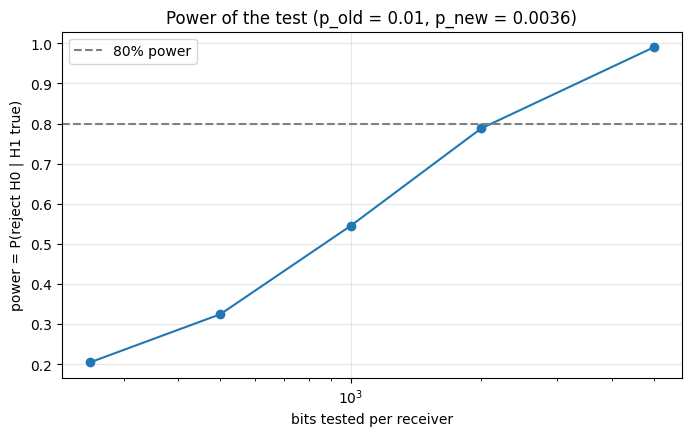

In [18]:
reps = 2_000
# Type I error rate: both receivers truly have p = 0.01 (H0 true)
x1 = rng.binomial(n_cmp, TARGET_BER, reps)
x2 = rng.binomial(n_cmp, TARGET_BER, reps)
type1 = np.mean(two_proportion_z(x1, n_cmp, x2, n_cmp)[1] < ALPHA)
print(f"Estimated Type I error rate = {type1:.3f}   (should be close to α = {ALPHA})")

# Power for different test sizes (H1 true: the new receiver has p = two_antenna_ber(0.5))
p_new = two_antenna_ber(0.5)
sizes = [250, 500, 1_000, 2_000, 5_000]
power = []
for n in sizes:
    x1 = rng.binomial(n, TARGET_BER, reps)
    x2 = rng.binomial(n, p_new, reps)
    power.append(np.mean(two_proportion_z(x1, n, x2, n)[1] < ALPHA))
    print(f"n = {n:5d} bits per receiver: power = {power[-1]:.3f},  Type II error β = {1 - power[-1]:.3f}")

plt.plot(sizes, power, "o-")
plt.axhline(0.8, color="gray", ls="--", label="80% power")
plt.xscale("log")
plt.xlabel("bits tested per receiver")
plt.ylabel("power = P(reject H0 | H1 true)")
plt.title(f"Power of the test (p_old = {TARGET_BER}, p_new = {p_new:.4f})")
plt.legend()
plt.show()

### 8.4 Bit detection *is* a hypothesis test
Deciding each bit is itself a test of $H_0$: "0 was sent" against $H_1$: "1 was sent".
* False alarm (Type I): $\alpha(\tau) = P(R > \tau \mid 0)$
* Miss (Type II): $\beta(\tau) = P(R < \tau \mid 1)$

Moving the threshold trades one error for the other. The **ROC curve** shows this trade-off.

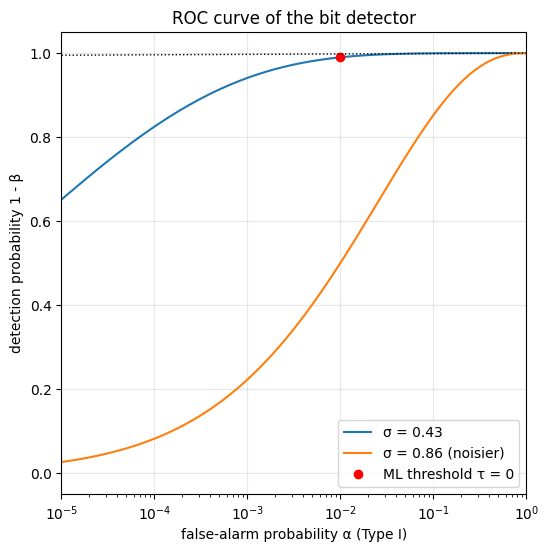

In [19]:
taus = np.linspace(-3, 3, 400)
alpha_tau = stats.norm.sf(taus, loc=-A, scale=SIGMA)
power_tau = stats.norm.sf(taus, loc=A, scale=SIGMA)
noisier = 2 * SIGMA

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(alpha_tau, power_tau, label=f"σ = {SIGMA:.2f}")
ax.plot(stats.norm.sf(taus, -A, noisier), stats.norm.sf(taus, A, noisier), label=f"σ = {noisier:.2f} (noisier)")
ax.plot(stats.norm.sf(0, -A, SIGMA), stats.norm.sf(0, A, SIGMA), "ro", label="ML threshold τ = 0")
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.set(xlabel="false-alarm probability α (Type I)", ylabel="detection probability 1 - β",
       title="ROC curve of the bit detector", xscale="log", xlim=(1e-5, 1))
ax.legend()
plt.show()

## 9. Regression analysis: error rate vs signal-to-noise ratio

Engineers measure the bit error rate (BER) at several signal-to-noise ratios (SNR) and fit a model. That model then predicts the SNR needed to meet a target. Theory suggests $\text{BER} = Q(\sqrt{\text{SNR}})$, and for large SNR
$$\ln(\text{BER}) \approx -\tfrac12\,\text{SNR} - \tfrac12 \ln(\text{SNR}) - \tfrac12\ln(2\pi),$$
so we fit:
* **Model 1 (simple linear regression):** $\ln(\text{BER}) = \beta_0 + \beta_1\,\text{SNR} + \varepsilon$
* **Model 2 (multiple regression):** $\ln(\text{BER}) = \beta_0 + \beta_1\,\text{SNR} + \beta_2 \ln(\text{SNR}) + \varepsilon$

In [20]:
snr_db = np.arange(0, 11)
snr_lin = 10 ** (snr_db / 10)
n_reg = 200_000
ber_measured = []
for snr in snr_lin:
    bits, received = transmit(n_reg, sigma=A / np.sqrt(snr))
    ber_measured.append(np.mean((received > 0) != bits))
ber_measured = np.array(ber_measured)
ber_theory = stats.norm.sf(np.sqrt(snr_lin))

print(" SNR (dB)   measured BER   theoretical BER")
for d, bm, bt in zip(snr_db, ber_measured, ber_theory):
    print(f"   {d:4d}     {bm:11.6f}     {bt:11.6f}")

 SNR (dB)   measured BER   theoretical BER
      0        0.157470        0.158655
      1        0.130765        0.130927
      2        0.104605        0.104029
      3        0.079120        0.078896
      4        0.056225        0.056495
      5        0.037845        0.037679
      6        0.022860        0.023007
      7        0.012790        0.012587
      8        0.005745        0.006004
      9        0.002495        0.002413
     10        0.000785        0.000783


In [21]:
y = np.log(ber_measured)
fit = stats.linregress(snr_lin, y)
t_crit = stats.t.isf(0.025, len(y) - 2)
print("Model 1: ln(BER) = β0 + β1·SNR")
print(f"  β0 = {fit.intercept:.4f},  β1 = {fit.slope:.4f}  (95% CI for β1: "
      f"{fit.slope - t_crit*fit.stderr:.4f} to {fit.slope + t_crit*fit.stderr:.4f})")
print(f"  correlation r = {fit.rvalue:.4f},  R² = {fit.rvalue**2:.4f},  p-value for β1 = {fit.pvalue:.2e}")

# Model 2 by least squares on the design matrix [1, SNR, ln SNR]
X = np.column_stack([np.ones_like(snr_lin), snr_lin, np.log(snr_lin)])
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
y_hat2 = X @ beta
r2_model2 = 1 - np.sum((y - y_hat2) ** 2) / np.sum((y - y.mean()) ** 2)
print("\nModel 2: ln(BER) = β0 + β1·SNR + β2·ln(SNR)")
print(f"  β0 = {beta[0]:.4f},  β1 = {beta[1]:.4f},  β2 = {beta[2]:.4f},  R² = {r2_model2:.5f}")

# Prediction: SNR needed for BER = 1e-3 (Model 1), compared with theory
target = 1e-3
snr_needed = (np.log(target) - fit.intercept) / fit.slope
snr_theory = stats.norm.isf(target) ** 2
print(f"\nSNR needed for BER = {target}: Model 1 predicts {10*np.log10(snr_needed):.2f} dB, "
      f"theory gives {10*np.log10(snr_theory):.2f} dB")

Model 1: ln(BER) = β0 + β1·SNR
  β0 = -1.3584,  β1 = -0.5882  (95% CI for β1: -0.6056 to -0.5708)
  correlation r = -0.9992,  R² = 0.9985,  p-value for β1 = 5.64e-14

Model 2: ln(BER) = β0 + β1·SNR + β2·ln(SNR)
  β0 = -1.3166,  β1 = -0.5179,  β2 = -0.2849,  R² = 0.99987

SNR needed for BER = 0.001: Model 1 predicts 9.75 dB, theory gives 9.80 dB


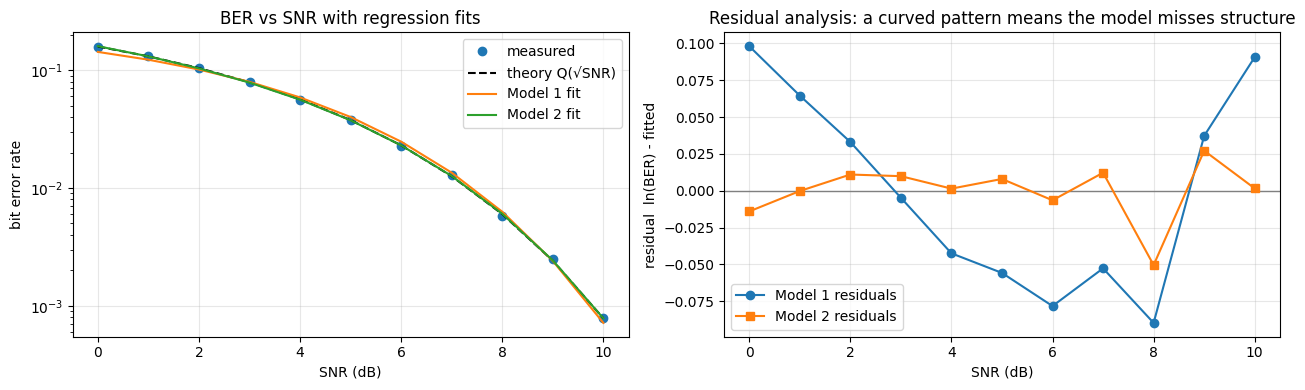

In [22]:
y_hat1 = fit.intercept + fit.slope * snr_lin
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].semilogy(snr_db, ber_measured, "o", label="measured")
axs[0].semilogy(snr_db, ber_theory, "k--", label="theory Q(√SNR)")
axs[0].semilogy(snr_db, np.exp(y_hat1), label="Model 1 fit")
axs[0].semilogy(snr_db, np.exp(y_hat2), label="Model 2 fit")
axs[0].set(xlabel="SNR (dB)", ylabel="bit error rate", title="BER vs SNR with regression fits")
axs[0].legend()
axs[1].axhline(0, color="gray", lw=1)
axs[1].plot(snr_db, y - y_hat1, "o-", label="Model 1 residuals")
axs[1].plot(snr_db, y - y_hat2, "s-", label="Model 2 residuals")
axs[1].set(xlabel="SNR (dB)", ylabel="residual  ln(BER) - fitted",
           title="Residual analysis: a curved pattern means the model misses structure")
axs[1].legend()
plt.tight_layout()
plt.show()

## 10. Monitoring the link: statistical quality control and process control

### 10.1 p-chart for packet failures (quality control)
Every hour, 500 packets are checked and the fraction $\hat p_i$ that failed is plotted.
* **Phase I:** 25 in-control hours set the centre line $\bar p$ and the limits $\bar p \pm 3\sqrt{\bar p(1-\bar p)/n}$.
* **Phase II:** new hours are monitored against those limits. A fault is simulated from hour 15 onwards: the bit error rate rises from 1.0% to 1.3%.

Two out-of-control rules are used: a point outside the limits, or 7 points in a row above the centre line.

Phase I: p̄ = 0.1384, LCL = 0.0921, UCL = 0.1847
Phase II: packet failure probability 0.1375 -> 0.2327 after hour 15
Hours outside the control limits: [np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29)]
First 'run of 7 above centre' signal at hour: 16


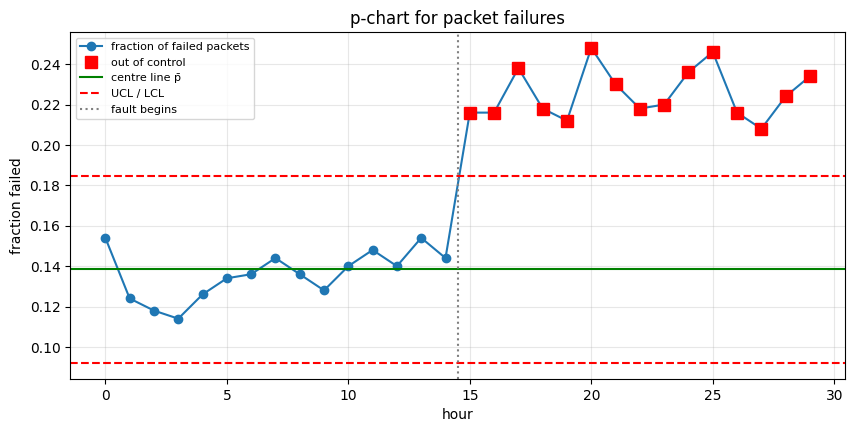

In [23]:
n_per_hour = 500
phase1 = rng.binomial(n_per_hour, P_FAIL, 25) / n_per_hour
p_bar = phase1.mean()
ucl = p_bar + 3 * np.sqrt(p_bar * (1 - p_bar) / n_per_hour)
lcl = max(0.0, p_bar - 3 * np.sqrt(p_bar * (1 - p_bar) / n_per_hour))
print(f"Phase I: p̄ = {p_bar:.4f}, LCL = {lcl:.4f}, UCL = {ucl:.4f}")

FAULT_HOUR = 15
P_FAIL_FAULT = stats.binom.sf(T_CORRECT, N_BITS, 0.013)
p_true = np.where(np.arange(30) < FAULT_HOUR, P_FAIL, P_FAIL_FAULT)
phase2 = rng.binomial(n_per_hour, p_true) / n_per_hour
print(f"Phase II: packet failure probability {P_FAIL:.4f} -> {P_FAIL_FAULT:.4f} after hour {FAULT_HOUR}")

def run_rule(values, centre, length=7):
    # Index where `length` consecutive points first lie above the centre line, or None
    run = 0
    for i, v in enumerate(values):
        run = run + 1 if v > centre else 0
        if run >= length:
            return i
    return None

outside = np.where((phase2 > ucl) | (phase2 < lcl))[0]
print("Hours outside the control limits:", list(outside))
print("First 'run of 7 above centre' signal at hour:", run_rule(phase2, p_bar))

hours = np.arange(len(phase2))
plt.figure(figsize=(10, 4.5))
plt.plot(hours, phase2, "o-", label="fraction of failed packets")
plt.plot(outside, phase2[outside], "rs", ms=9, label="out of control")
plt.axhline(p_bar, color="g", label="centre line p̄")
plt.axhline(ucl, color="r", ls="--", label="UCL / LCL")
plt.axhline(lcl, color="r", ls="--")
plt.axvline(FAULT_HOUR - 0.5, color="gray", ls=":", label="fault begins")
plt.xlabel("hour")
plt.ylabel("fraction failed")
plt.title("p-chart for packet failures")
plt.legend(fontsize=8)
plt.show()

### 10.2 x̄-chart for receiver drift (process control)
Every hour, 5 noise-only measurements are averaged. With target mean $\mu_0 = 0$ and known $\sigma$, the control limits are $\mu_0 \pm 3\sigma/\sqrt5$. From hour 20 the receiver's offset slowly **drifts** upwards by 0.02 V per hour.

Control limits: ±0.5767
Hours signalling out of control: [np.int64(35), np.int64(36), np.int64(39)]
First alarm at hour 35, i.e. 16 hours after the drift started


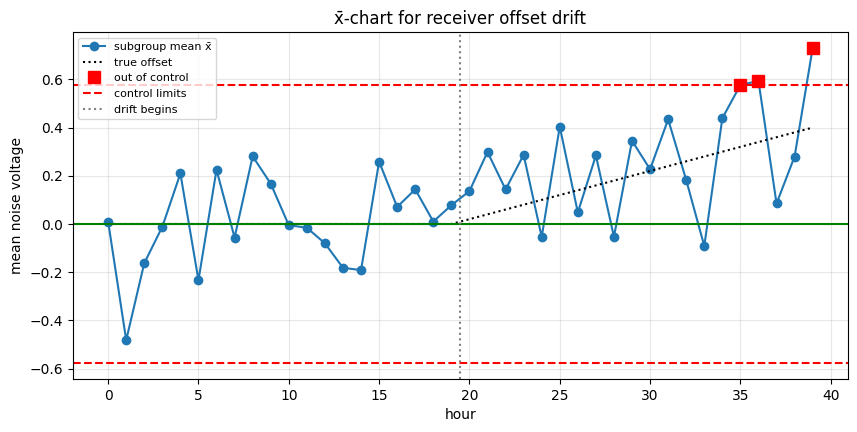

In [24]:
n_sub, hours_total, DRIFT_START = 5, 40, 20
drift = np.where(np.arange(hours_total) >= DRIFT_START, 0.02 * (np.arange(hours_total) - DRIFT_START + 1), 0.0)
subgroups = rng.normal(drift[:, None], SIGMA, size=(hours_total, n_sub))
x_bars = subgroups.mean(axis=1)
limit = 3 * SIGMA / np.sqrt(n_sub)
out = np.where(np.abs(x_bars) > limit)[0]
print(f"Control limits: ±{limit:.4f}")
print("Hours signalling out of control:", list(out))
if len(out):
    print(f"First alarm at hour {out[0]}, i.e. {out[0] - DRIFT_START + 1} hours after the drift started")

plt.figure(figsize=(10, 4.5))
plt.plot(x_bars, "o-", label="subgroup mean x̄")
plt.plot(drift, "k:", label="true offset")
plt.plot(out, x_bars[out], "rs", ms=9, label="out of control")
plt.axhline(0, color="g")
plt.axhline(limit, color="r", ls="--", label="control limits")
plt.axhline(-limit, color="r", ls="--")
plt.axvline(DRIFT_START - 0.5, color="gray", ls=":", label="drift begins")
plt.xlabel("hour")
plt.ylabel("mean noise voltage")
plt.title("x̄-chart for receiver offset drift")
plt.legend(fontsize=8)
plt.show()

## 11. Speech detection: a statistical first step in speech recognition

Before a speech recogniser can work out *what* was said, it must decide *when* someone is speaking. This step is called **voice activity detection**. We generate a 4-second audio clip (8 kHz) containing synthetic voiced speech and background noise. We then:
1. split the audio into 20 ms frames and compute each frame's **log-energy** (in dB)
2. **estimate** a normal model for the log-energy of speech frames and of noise frames from a training clip
3. classify the frames of a **new** clip with the **Bayes decision rule**
4. measure the false-alarm (Type I) and miss (Type II) rates

In [25]:
FS = 8000          # sampling rate (samples per second)
FRAME = 160        # 20 ms frames

def make_clip(segments, duration=4.0, noise_sd=0.05):
    tt = np.arange(int(duration * FS)) / FS
    f0 = 140 + 30 * np.sin(2 * np.pi * 0.7 * tt)                 # slowly varying pitch (Hz)
    phase = 2 * np.pi * np.cumsum(f0) / FS
    voiced = sum(np.sin(h * phase) / h for h in range(1, 6))     # pitch + 4 harmonics
    speech = np.zeros_like(tt)
    mask = np.zeros(tt.size, dtype=bool)
    for start, end in segments:
        idx = (tt >= start) & (tt < end)
        envelope = np.sin(np.pi * (tt[idx] - start) / (end - start)) ** 0.5
        speech[idx] = 0.3 * envelope * voiced[idx]
        mask[idx] = True
    return tt, speech + rng.normal(0, noise_sd, tt.size), mask

def frame_features(signal, mask):
    n_frames = signal.size // FRAME
    frames = signal[: n_frames * FRAME].reshape(n_frames, FRAME)
    log_energy = 10 * np.log10(np.mean(frames ** 2, axis=1) + 1e-12)
    labels = mask[: n_frames * FRAME].reshape(n_frames, FRAME).mean(axis=1) > 0.5
    return log_energy, labels

_, train_sig, train_mask = make_clip([(0.3, 1.0), (1.4, 2.3), (2.8, 3.6)])
tt, test_sig, test_mask = make_clip([(0.2, 0.8), (1.2, 1.6), (2.0, 3.0), (3.3, 3.8)])
train_x, train_y = frame_features(train_sig, train_mask)
test_x, test_y = frame_features(test_sig, test_mask)

# Estimation: fit a normal model to each class
mu_s, sd_s = train_x[train_y].mean(), train_x[train_y].std(ddof=1)
mu_n, sd_n = train_x[~train_y].mean(), train_x[~train_y].std(ddof=1)
prior_s = train_y.mean()
print(f"Speech frames: log-energy ~ N({mu_s:.2f}, {sd_s:.2f}²)   ({train_y.sum()} frames)")
print(f"Noise  frames: log-energy ~ N({mu_n:.2f}, {sd_n:.2f}²)   ({(~train_y).sum()} frames)")
print(f"Prior P(speech) = {prior_s:.3f}")

# Welch two-sample t-test: do speech and noise frames really differ in energy?
t_stat, p_value = stats.ttest_ind(train_x[train_y], train_x[~train_y], equal_var=False)
print(f"Welch t-test of equal mean log-energy: t = {t_stat:.2f}, p-value = {p_value:.2e}")

Speech frames: log-energy ~ N(-14.31, 3.06²)   (120 frames)
Noise  frames: log-energy ~ N(-26.03, 0.46²)   (80 frames)
Prior P(speech) = 0.600
Welch t-test of equal mean log-energy: t = 41.24, p-value = 2.43e-75


In [26]:
def classify(x):
    # Bayes rule: choose the class with the larger posterior probability
    log_post_s = stats.norm.logpdf(x, mu_s, sd_s) + np.log(prior_s)
    log_post_n = stats.norm.logpdf(x, mu_n, sd_n) + np.log(1 - prior_s)
    return log_post_s > log_post_n

pred = classify(test_x)
tp = np.sum(pred & test_y)
tn = np.sum(~pred & ~test_y)
fp = np.sum(pred & ~test_y)
fn = np.sum(~pred & test_y)

print("Confusion matrix on the NEW clip (rows = truth, columns = decision)")
print(f"                 decided noise   decided speech")
print(f"  true noise     {tn:12d}   {fp:14d}")
print(f"  true speech    {fn:12d}   {tp:14d}")
print(f"\nAccuracy               = {(tp + tn) / len(test_y):.3f}")
print(f"False-alarm rate (I)   = {fp / (fp + tn):.3f}")
print(f"Miss rate (II)         = {fn / (fn + tp):.3f}")

Confusion matrix on the NEW clip (rows = truth, columns = decision)
                 decided noise   decided speech
  true noise               75                0
  true speech               1              124

Accuracy               = 0.995
False-alarm rate (I)   = 0.000
Miss rate (II)         = 0.008


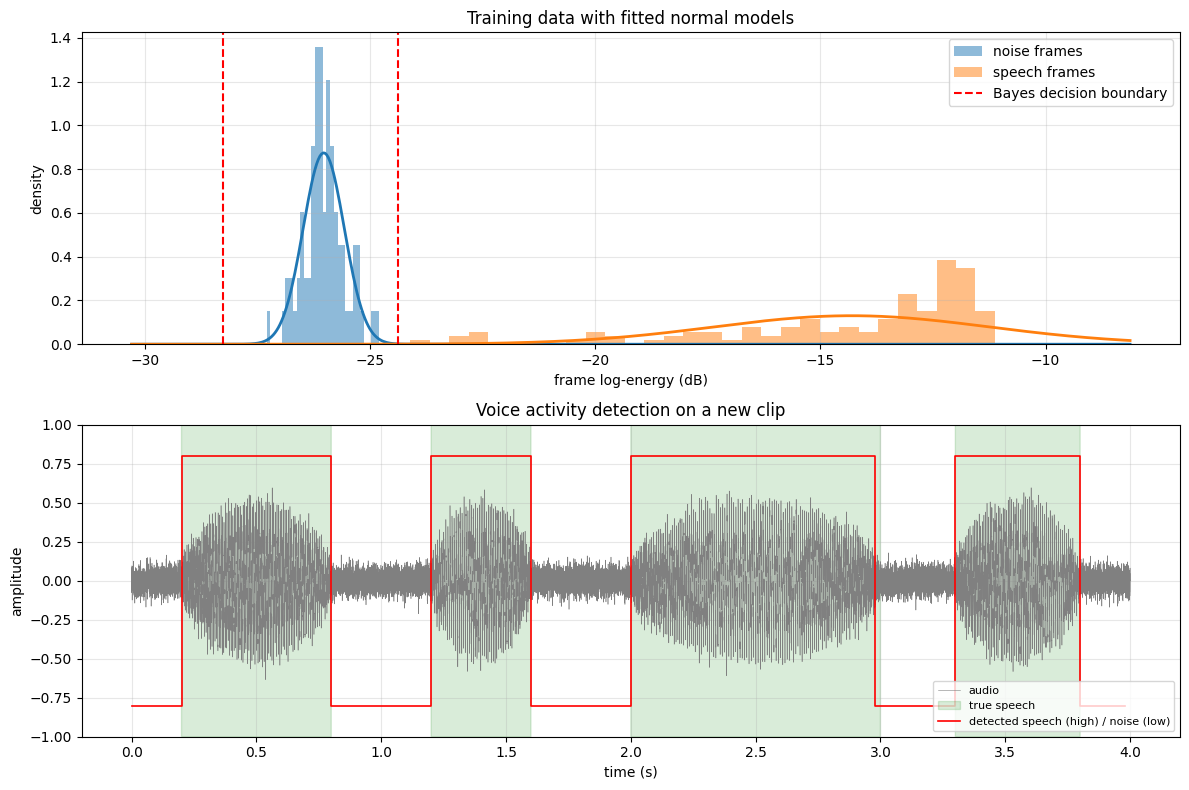

In [27]:
grid = np.linspace(min(train_x.min(), test_x.min()) - 3, max(train_x.max(), test_x.max()) + 3, 600)
boundaries = grid[np.where(np.diff(classify(grid).astype(int)) != 0)[0]]

fig, axs = plt.subplots(2, 1, figsize=(12, 8))
axs[0].hist(train_x[~train_y], bins=30, density=True, alpha=0.5, label="noise frames")
axs[0].hist(train_x[train_y], bins=30, density=True, alpha=0.5, label="speech frames")
axs[0].plot(grid, stats.norm.pdf(grid, mu_n, sd_n), "C0", lw=2)
axs[0].plot(grid, stats.norm.pdf(grid, mu_s, sd_s), "C1", lw=2)
for i, b in enumerate(boundaries):
    axs[0].axvline(b, color="r", ls="--", label="Bayes decision boundary" if i == 0 else None)
axs[0].set(xlabel="frame log-energy (dB)", ylabel="density", title="Training data with fitted normal models")
axs[0].legend()

frame_times = np.arange(len(test_x)) * FRAME / FS
axs[1].plot(tt, test_sig, lw=0.4, color="gray", label="audio")
axs[1].fill_between(tt, -1, 1, where=test_mask, color="green", alpha=0.15, label="true speech")
axs[1].step(frame_times, np.where(pred, 0.8, -0.8), where="post", color="r", lw=1.2, label="detected speech (high) / noise (low)")
axs[1].set(xlabel="time (s)", ylabel="amplitude", ylim=(-1, 1), title="Voice activity detection on a new clip")
axs[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 12. Results summary and conclusion

In [28]:
summary = {
    "Packet arrival rate estimate λ̂ (packets/s)": 1 / g_bar,
    "Single-antenna BER (theory)": TARGET_BER,
    "MAP vs ML BER with P(1)=0.7": f"{error_probability(map_threshold(P1), P1):.5f} vs {error_probability(0.0, P1):.5f}",
    "Packet failure probability (n=128, t=2)": P_FAIL,
    "Two-antenna BER, ρ = 0 / 0.5 / 0.9": " / ".join(f"{two_antenna_ber(r):.5f}" for r in [0.0, 0.5, 0.9]),
    "Estimated BER from 20,000-bit test": errors / n_test,
    "Two-proportion test p-value (new vs old)": f"{p_value_cmp:.2e}",
    "Regression R² (Model 1 / Model 2)": f"{fit.rvalue**2:.4f} / {r2_model2:.5f}",
    "SNR for BER = 1e-3 (Model 1, dB)": 10 * np.log10(snr_needed),
    "Speech detector accuracy": (tp + tn) / len(test_y),
}
for key, val in summary.items():
    print(f"{key:45s} {val:.5f}" if isinstance(val, float) else f"{key:45s} {val}")

Packet arrival rate estimate λ̂ (packets/s)   4.85475
Single-antenna BER (theory)                   0.01000
MAP vs ML BER with P(1)=0.7                   0.00905 vs 0.01000
Packet failure probability (n=128, t=2)       0.13748
Two-antenna BER, ρ = 0 / 0.5 / 0.9            0.00050 / 0.00361 / 0.00850
Estimated BER from 20,000-bit test            0.00980
Two-proportion test p-value (new vs old)      8.43e-05
Regression R² (Model 1 / Model 2)             0.9985 / 0.99987
SNR for BER = 1e-3 (Model 1, dB)              9.74712
Speech detector accuracy                      0.99500


### Conclusion
This project used one engineering system, a noisy digital communication link, to apply the whole SENG 302 syllabus:

* **Discrete and continuous random variables:** packet counts followed the **Poisson** distribution and the gaps between packets followed the **exponential** distribution, including its memoryless property.
* **Conditional probability and Bayes' theorem**, with the **normal** distribution, gave the optimal receiver. Using prior information (MAP) lowered the error rate.
* **Counting techniques** and the **binomial** distribution gave the probability that a packet could not be corrected. The **Poisson approximation** was close to the exact value.
* **Joint distributions, covariance and correlation** showed that a second antenna helps most when its noise is uncorrelated with the first.
* The **central limit theorem** explained why channel noise is modelled as normal. **Sampling distributions** described how sample means behave.
* **Estimation** produced point estimates and confidence intervals. A coverage experiment showed why the Wilson interval is preferred for small error rates.
* **Hypothesis tests** (t-test, two-proportion z-test) detected a faulty receiver and confirmed an improvement. **Type I/II errors**, power and the ROC curve showed the trade-offs involved.
* **Regression analysis** modelled BER against SNR and predicted the SNR needed for a target error rate. Residual analysis compared the two models.
* **Quality control** (p-chart) and **process control** (x̄-chart) charts detected a simulated fault and a slow drift.
* A Gaussian **Bayes classifier** detected speech in noisy audio, which is the first stage of **speech recognition**.

### Possible extensions
* Replace the synthetic audio with real recordings (for example, uploaded `.wav` files).
* Add a fading channel (Rayleigh distribution) and compare it with the Gaussian channel.
* Use CUSUM or EWMA control charts to detect small drifts faster.